In [2]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from model_setup import X, y, groups

spw = (y == 0).sum() / (y == 1).sum()
model = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                      scale_pos_weight=spw, random_state=42, eval_metric="logloss")
model.fit(X, y)

Rows: 26857 | Schools: 2789
Share labeled high completion: 0.156


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


UGDS_LOG           4.868
PCTFLOAN           0.603
PCTPELL            0.570
B01003_001E_LOG    0.406
B19013_001E        0.278
S1501_C02_010E     0.276
UG25ABV            0.233
B20004_003E        0.222
S2301_C04_001E     0.206
S2301_C02_001E     0.196
CTRL_1.0           0.195
S1501_C02_014E     0.189
dtype: float32


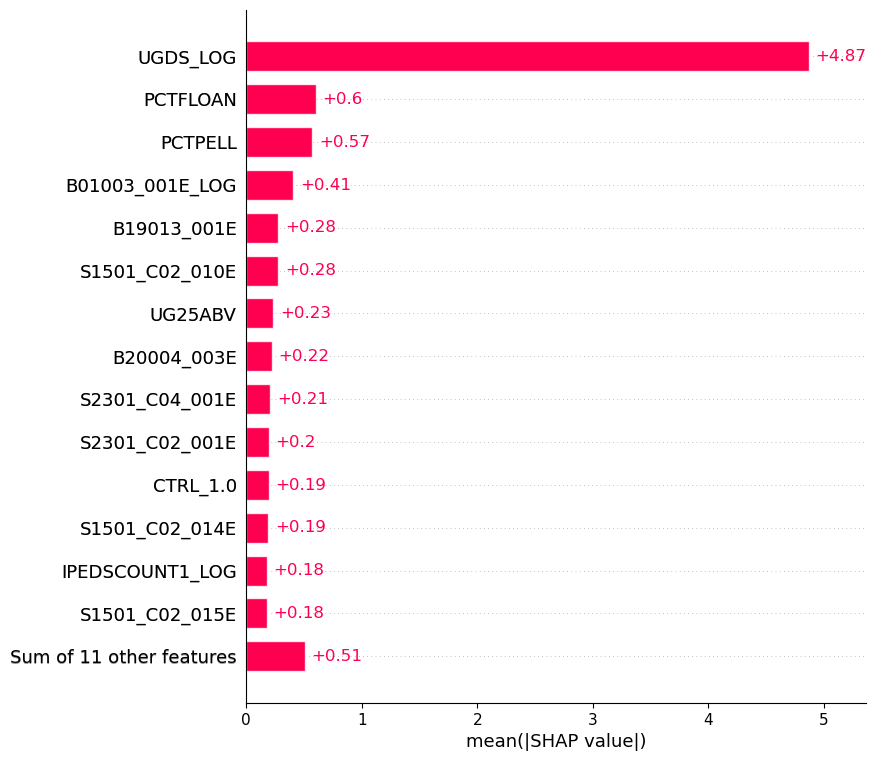

In [3]:
sample = X.sample(3000, random_state=42)   # a sample keeps the plots fast
explainer = shap.TreeExplainer(model)
sv = explainer(sample)

imp = pd.Series(np.abs(sv.values).mean(axis=0), index=X.columns).sort_values(ascending=False)
print(imp.head(12).round(3))
shap.plots.bar(sv, max_display=15)

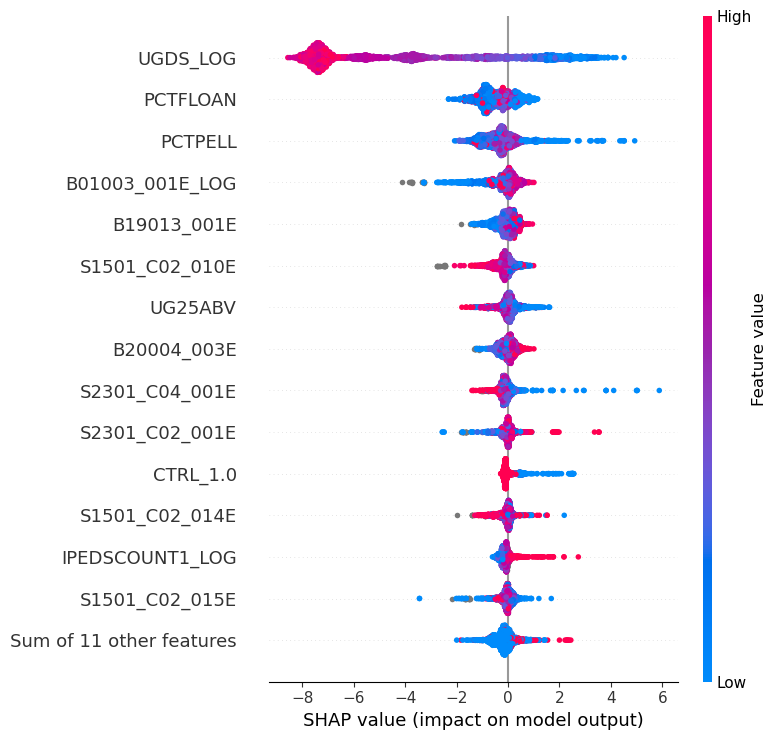

In [4]:
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.tight_layout()
plt.savefig("shap_national_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

CHECK

In [5]:
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_validate, GroupKFold
from xgboost import XGBClassifier
from model_setup import X, y, groups

size = np.expm1(X["UGDS_LOG"])
bands = pd.cut(size, [0, 100, 500, 2000, 10000, 1e7],
               labels=["under 100", "100-500", "500-2,000", "2,000-10,000", "over 10,000"])
print(pd.DataFrame({"band": bands, "y": y}).groupby("band", observed=True)["y"].agg(["size", "mean"]).round(2))

spw = (y == 0).sum() / (y == 1).sum()
xgb = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                    scale_pos_weight=spw, random_state=42, eval_metric="logloss")

def run(cols, name):
    r = cross_validate(xgb, X[cols], y, cv=GroupKFold(5), groups=groups, scoring=["roc_auc", "f1"])
    print(name, "| ROC-AUC", r["test_roc_auc"].mean().round(3), "| F1", r["test_f1"].mean().round(3))

run(["UGDS_LOG"], "school size only")
run([c for c in X.columns if c != "UGDS_LOG"], "everything except school size")

               size  mean
band                     
under 100      1604  0.65
100-500        4172  0.51
500-2,000      7492  0.12
2,000-10,000  10437  0.01
over 10,000    3139  0.00
school size only | ROC-AUC 0.882 | F1 0.552
everything except school size | ROC-AUC 0.904 | F1 0.617


CHECK 2

In [6]:
import pandas as pd
from model_setup import X, y
ctrl = X[["CTRL_1.0", "CTRL_2.0", "CTRL_3.0"]].idxmax(axis=1).map(
    {"CTRL_1.0": "public", "CTRL_2.0": "private nonprofit", "CTRL_3.0": "private for-profit"})
print(pd.DataFrame({"control": ctrl, "y": y}).groupby("control")["y"].agg(["size", "mean"]).round(2))

                     size  mean
control                        
private for-profit   3966  0.45
private nonprofit     378  0.52
public              22513  0.10


Next: SHAP on the Colorado model

Rows: 343 | Schools: 22
Share labeled 1: 0.417
CIP_FAMILY         1.025
IPEDSCOUNT1_LOG    0.374
PCTFLOAN           0.185
UG25ABV            0.105
S2301_C04_001E     0.099
UGDS_LOG           0.098
B19013_001E        0.079
PCTPELL            0.077
S2301_C02_001E     0.051
S1501_C02_014E     0.046
dtype: float32


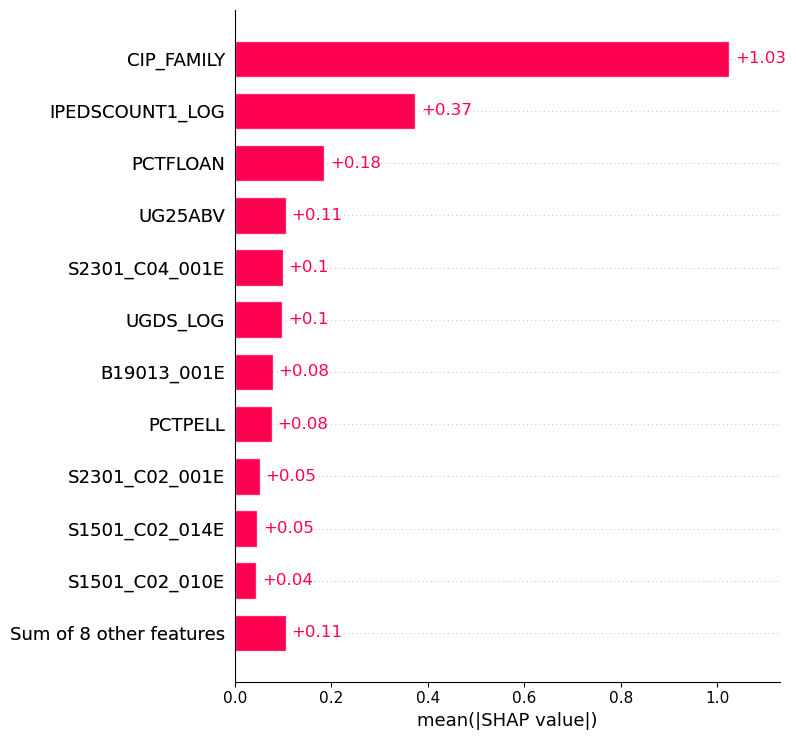

In [7]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, shap, matplotlib.pyplot as plt
from xgboost import XGBClassifier
from model_setup_colorado import df, X, y, groups

model = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                      subsample=0.8, random_state=42, eval_metric="logloss")
model.fit(X, y)
sv = shap.TreeExplainer(model)(X)

imp = pd.Series(np.abs(sv.values).mean(axis=0), index=X.columns).sort_values(ascending=False)
print(imp.head(10).round(3))

shap.plots.bar(sv, max_display=12, show=False)
plt.tight_layout()
plt.savefig("shap_colorado_bar.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
i = list(X.columns).index("CIP_FAMILY")
by_subject = (pd.DataFrame({"CIP_FAMILY": df["CIP_FAMILY"].values, "shap": sv.values[:, i]})
                .groupby("CIP_FAMILY")["shap"].agg(["size", "mean"]).sort_values("mean"))
display(by_subject[by_subject["size"] >= 15].round(2))

,size,mean
CIP_FAMILY,,
13,17,-2.06
12,19,-2.05
51,110,-0.76
47,24,-0.45
48,21,-0.45
52,33,0.76
15,21,1.12
46,20,1.17
43,23,1.71
